<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 05: Transients and small-signal analysis

**Goals.** Simulate transient experiments (photo-CELIV, TPV, TPC) and small-signal spectroscopy
(admittance, IMPS, IMVS) with the transient DD solver.

### Theory
In CELIV, a voltage ramp $V=At$ extracts the carriers. Juška's formula gives
$\mu=\dfrac{2d^2}{3At_{max}^2}$ when the extracted charge is small. Small-signal analysis linearises the DD
equations about a dc operating point: $Y(\omega)=G+i\omega C$. For trap-free SCLC,
$C(0)=\tfrac34C_{geo}$ and $\tau_{dc}=\tfrac43L^2/(\mu V)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


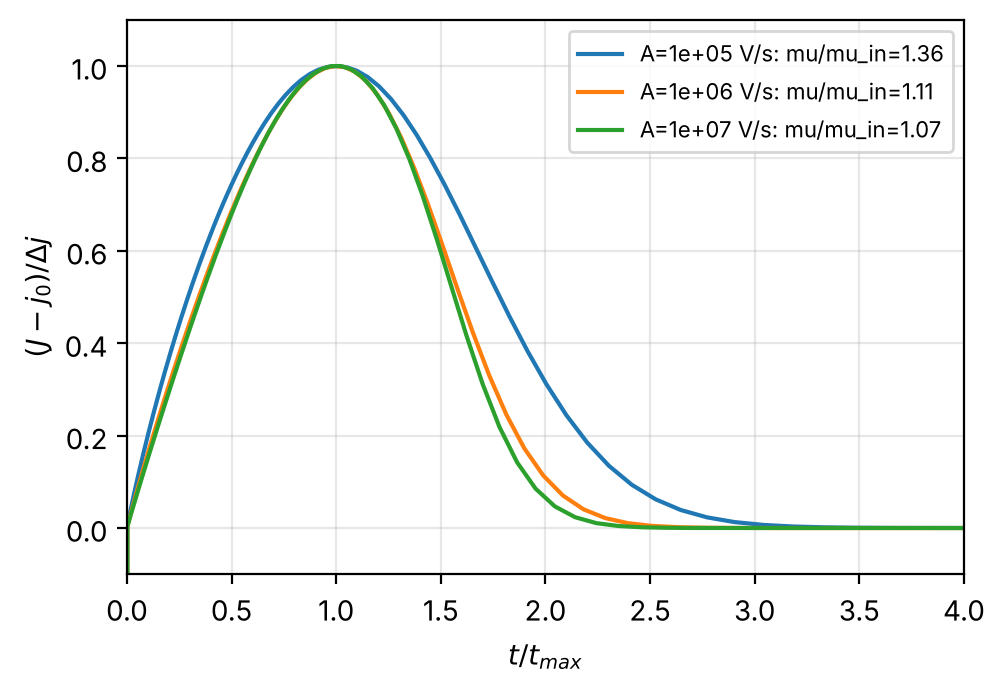

In [2]:
from orchid.drift_diffusion import Device
from orchid.transient import celiv
mu = 1e-8
fig, ax = plt.subplots()
for A in (1e5, 1e6, 1e7):
    t_est = 1e-7 * np.sqrt(2 / (3 * mu * A))
    d = Device(L=100e-9, N=121, Eg=2.0, phi_anode_p=1.0, phi_cathode_n=1.0, mu_n=1e-14, mu_p=mu,
               recombination=False, grid_beta=2.0)
    r = celiv(d, A=A, t_end=12 * t_est, n_t=200, G_pulse=1e30, t_pulse=1e-10)
    ax.plot(r["t"] / r["t_max"], (r["J"] - r["j0"]) / r["dj"], label=f"A={A:.0e} V/s: mu/mu_in={r['mu_juska']/mu:.2f}")
ax.set_xlim(0, 4); ax.set_ylim(-0.1, 1.1); ax.set_xlabel(r"$t/t_{max}$"); ax.set_ylabel(r"$(J-j_0)/\Delta j$"); ax.legend(fontsize=8);

The extracted mobility converges to the input mobility at fast ramps, once $qAt_{max}\gg kT$.

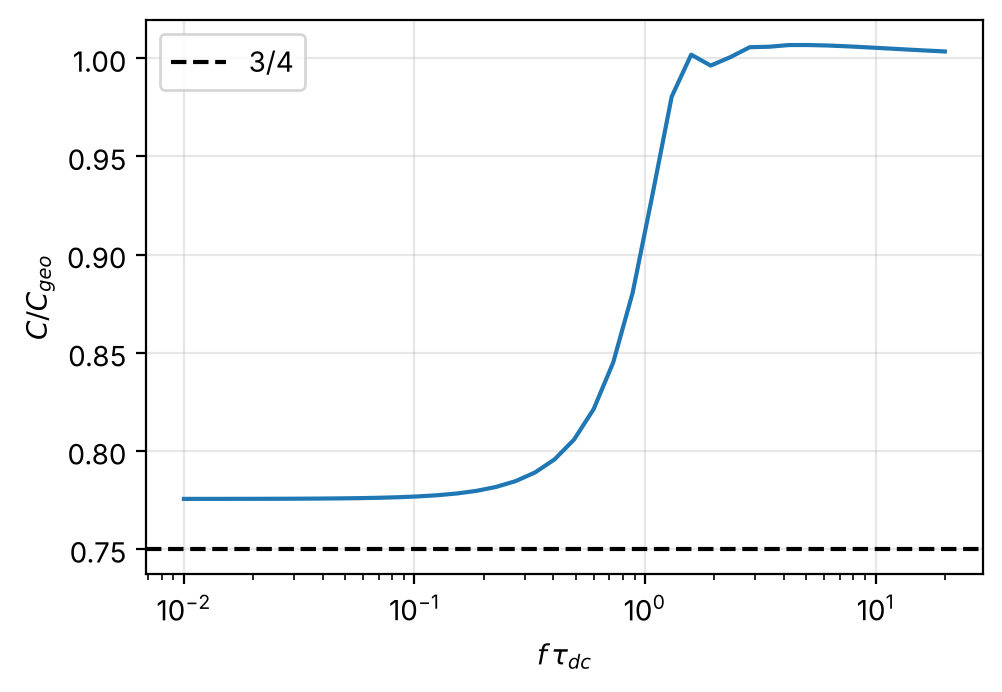

In [3]:
from orchid.smallsignal import admittance
from orchid.constants import eps0
L, Vb = 100e-9, 20.0
d = Device(L=L, N=161, Eg=2.4, phi_anode_p=0.0, phi_cathode_n=1.0, mu_n=1e-12, mu_p=mu, recombination=False)
tdc = 4 / 3 * L**2 / (mu * (Vb - 1.4))
f = np.logspace(-2, 1.3, 40) / tdc
r = admittance(d, Vb, f)
Cg = eps0 * 3.5 / L
plt.semilogx(f * tdc, r["C"] / Cg); plt.axhline(0.75, c="k", ls="--", label="3/4")
plt.xlabel(r"$f\,\tau_{dc}$"); plt.ylabel(r"$C/C_{geo}$"); plt.legend();

Voc = 0.616 V, TPV lifetime 5.88 us, bulk 1/(2 gamma n) = 1.56 us


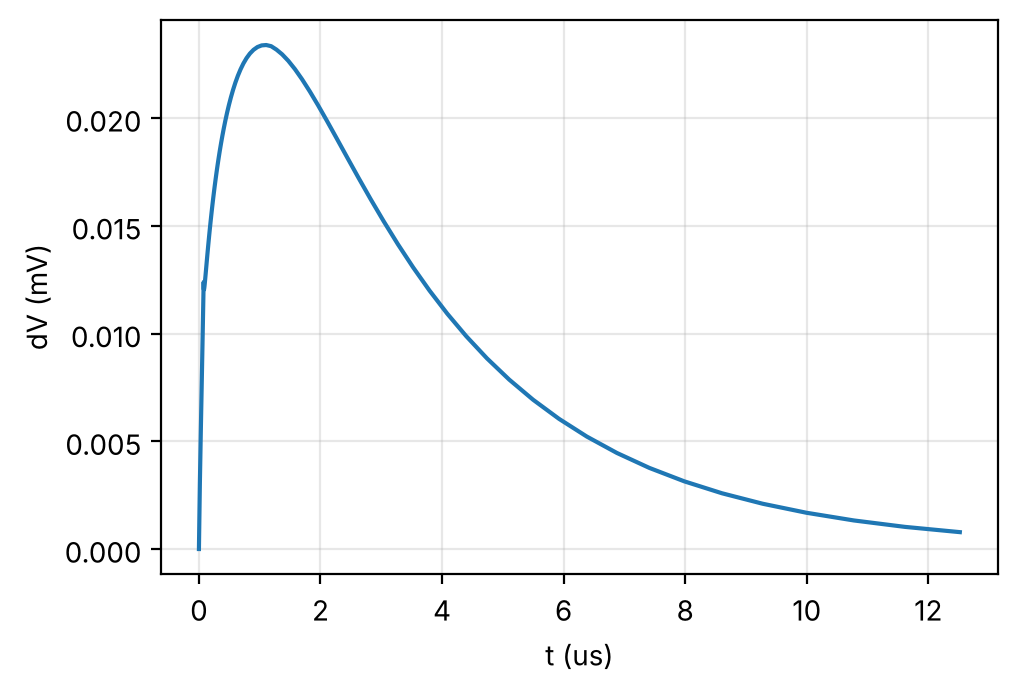

In [4]:
from orchid.transient import tpv
d = Device(L=100e-9, N=101, Eg=1.2, phi_anode_p=0.1, phi_cathode_n=0.1, mu_n=1e-8, mu_p=1e-8, G=1e27)
r = tpv(d)
print(f"Voc = {r['Voc']:.3f} V, TPV lifetime {r['tau']*1e6:.2f} us, bulk 1/(2 gamma n) = {r['tau_langevin']*1e6:.2f} us")
plt.plot(r["t"] * 1e6, r["dV"] * 1e3); plt.xlabel("t (us)"); plt.ylabel("dV (mV)");

**Exercise.** Compute an IMPS spectrum with `orchid.smallsignal.imps(dev, 0.0, freqs)` for the illuminated device above and find the frequency of the minimum of Im H.

<details><summary>Solution</summary>

```python
from orchid.smallsignal import imps
freqs = np.logspace(3, 9, 40)
h = imps(d, 0.0, freqs)['H']
print(freqs[np.argmin(h.imag)])
```
The characteristic frequency is about $1/(2\pi\tau)$ for the slowest transport or recombination process.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("05", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 05`.

In [5]:
from orchid.tutorials import quiz
quiz("05")

Quiz 05: Transients and small-signal analysis

Q1. Photo-CELIV extracts the mobility (Juska et al. 2000, small-charge limit) from
    (a) mu = d^2 / (V t_tr)
    (b) mu = A t_max / d
    (c) mu = 2 d^2 / (3 A t_max^2)
    (d) mu = j0 / dj

Q2. The low-frequency capacitance of a trap-free single-carrier SCLC diode is
    (a) C_geo
    (b) 3/4 C_geo
    (c) 1/2 C_geo
    (d) 2 C_geo

Q3. What does a small-perturbation transient photovoltage (TPV) measure?
    (a) The transit time
    (b) The lifetime of the excess carriers at open circuit
    (c) The exciton diffusion length
    (d) The series resistance

Q4. IMPS modulates ____ and measures ____.
    (a) voltage; current
    (b) light intensity; photocurrent at short circuit
    (c) temperature; current
    (d) light; photovoltage at open circuit

Q5. The dc transit time of a trap-free SCLC diode is
    (a) 3/4 L^2 / (mu V)
    (b) L^2 / (mu V)
    (c) 4/3 L^2/(mu V)
    (d) L / (mu V)

Answer with quiz("05", answers="....."), one lette

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("05", answers=".....")

<details><summary>Answer key</summary>

`cbbbc`. Run `quiz("05", answers="cbbbc")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`